# A C-band radar outside the US: Anjalankoski (Finland), 30 Aug 2023

**Question.** Everything so far ran on US NEXRAD S-band data. India's network is mostly C band, in a different
file format and without HRRR or MRMS. Does the same chain work on a C-band radar from another country, with only
public data, and how close is it to rain gauges?

**Data (all open, no account).** Finnish Meteorological Institute (FMI): dual-pol C-band volumes every 5 minutes in
ODIM HDF5 (the European standard) on AWS, and hourly gauges from the FMI open-data service. 30 Aug 2023,
12-16 UTC: the wettest widespread afternoon of summer 2023 in south-east Finland.

**What changes for C band.** ODIM reader; band C settings (alpha = 0.08 dB/deg; R(A) used from 5 deg of PHIDP
span); the drop-size-adaptive alpha of notebook 05 is an S-band method and is not used; the 0 C height prior comes
from the 2 m temperature (ERA5 via Open-Meteo) because HRRR covers only the US. No MRMS: the reference is the gauges.

In [1]:
# Colab: uncomment to install
!pip install -q pysteps opencv-python-headless rasterio "git+https://github.com/manmeet3591/radarwow-pipeline" "git+https://github.com/manmeet3591/radarwow-merging"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.core import diagnose, fmi_aws_files, open_volume
from radarwow.merging import leave_one_out, radar_at
from radarwow.pipeline import hourly_totals
from radarwow.verify import basic_qc, fetch_fmi, gross_error_qc

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
SITE, START, END = "fianj", "2023-08-30 12:00", "2023-08-30 16:00"
RATES = {"synthetic": "synthetic (R(A), R(KDP), R(Z))", "marshall_palmer": "Z-R Marshall-Palmer"}

## 1. What the file looks like
The health check from `radarwow.core.diagnose`, on the first volume.

In [3]:
f0 = fmi_aws_files(SITE, START, pd.Timestamp(START) + pd.Timedelta(minutes=5), cache_dir=f"{CACHE}/fmi")[0][1]
dt0 = open_volume(f0, band="C")
lat0, lon0, alt = (float(dt0[k].values) for k in ("latitude", "longitude", "altitude"))
display(Markdown(f"Radar at {lat0:.3f} N, {lon0:.3f} E, {alt:.0f} m; "
                 + ", ".join(f"{float(np.nanmedian(dt0[n].to_dataset()['elevation'].values)):.1f} deg" for n in sorted(
                     (k for k in dt0.children if k.startswith("sweep")), key=lambda s: int(s.split('_')[1])))))
display(diagnose(dt0))

Radar at 60.904 N, 27.108 E, 139 m; 0.3 deg, 0.7 deg, 1.5 deg, 3.0 deg, 5.0 deg, 9.0 deg, 2.0 deg, 7.0 deg, 11.0 deg, 15.0 deg, 25.0 deg, 45.0 deg, 0.4 deg

**None** (band C, sweep_0)

| severity | topic | finding | remedy |
|---|---|---|---|
| fix | noise | noise gates are stored, not censored (floor ~-375 dBZ at 1 km, rising 20 log r); 52% of gates are signal | qc: signal mask (SNR or noise-floor + 3 dB) before any other step |
| fix | PHIDP | system PHIDP offset ~66 deg (median of first rain gates) | kdp: subtract offset / use offset-free derivative (Vulpiani 2012) |
| info | clutter | both total (DBTH) and filtered (DBZH) reflectivity present | DBTH - DBZH = clutter power removed by the signal processor |
| info | ZDR | median ZDR in light rain +0.27 dB: no large bias |  |

## 2. Hourly totals against the gauges

In [4]:
rad = {k: hourly_totals(SITE, START, END, n_tilts=3, blockage=True, source="fmi", rate=k) for k in RATES}
g = fetch_fmi(lat0, lon0, 145, START, END, f"{CACHE}/gauges")
g["gx"] = (g["lon"] - lon0) * 111.2 * np.cos(np.deg2rad(lat0))
g["gy"] = (g["lat"] - lat0) * 111.2
x, y = rad["synthetic"]["x"].values, rad["synthetic"]["y"].values
for k in RATES:
    g[k] = np.nan
    for t, idx in g.groupby("time").groups.items():
        g.loc[idx, k] = radar_at(rad[k]["RAIN"].sel(time=t).values, x, y, g.loc[idx, "gx"].values, g.loc[idx, "gy"].values)
g = gross_error_qc(basic_qc(g, radar_col="synthetic"), radar_col="synthetic")
display(Markdown(f"{g.station.nunique()} gauges within 145 km, {len(g)} gauge-hours. Quality control: "
                 + ", ".join(f"{k}: {v}" for k, v in g["qc"].value_counts().items())))
ok = g[g.qc == "ok"]


def stats(e, r):
    m = np.isfinite(e) & np.isfinite(r)
    e, r = e[m], r[m]
    return dict(n=int(m.sum()), bias=e.sum() / r.sum(), MAE=np.mean(np.abs(e - r)), corr=np.corrcoef(e, r)[0, 1])


rows = [dict(estimate=RATES[k], **stats(ok[k].values, ok["gauge_mm"].values)) for k in RATES]
rows += [dict(estimate=f"{RATES[k]}, hour {t:%H}-{t.hour + 1:02d}", **stats(d[k].values, d["gauge_mm"].values))
         for k in ["synthetic"] for t, d in ok.groupby("time")]
display(Markdown("**Radar at the gauges** (bias = radar total / gauge total; MAE in mm)\n\n" + pd.DataFrame(rows).round(2).to_markdown(index=False)))

21 gauges within 145 km, 84 gauge-hours. Quality control: ok: 84

**Radar at the gauges** (bias = radar total / gauge total; MAE in mm)

| estimate                                   |   n |   bias |   MAE |   corr |
|:-------------------------------------------|----:|-------:|------:|-------:|
| synthetic (R(A), R(KDP), R(Z))             |  84 |   0.36 |  1.08 |   0.86 |
| Z-R Marshall-Palmer                        |  84 |   0.32 |  1.13 |   0.88 |
| synthetic (R(A), R(KDP), R(Z)), hour 12-13 |  21 |   0.53 |  1.03 |   0.91 |
| synthetic (R(A), R(KDP), R(Z)), hour 13-14 |  21 |   0.31 |  1.29 |   0.89 |
| synthetic (R(A), R(KDP), R(Z)), hour 14-15 |  21 |   0.28 |  1.08 |   0.88 |
| synthetic (R(A), R(KDP), R(Z)), hour 15-16 |  21 |   0.3  |  0.9  |   0.9  |

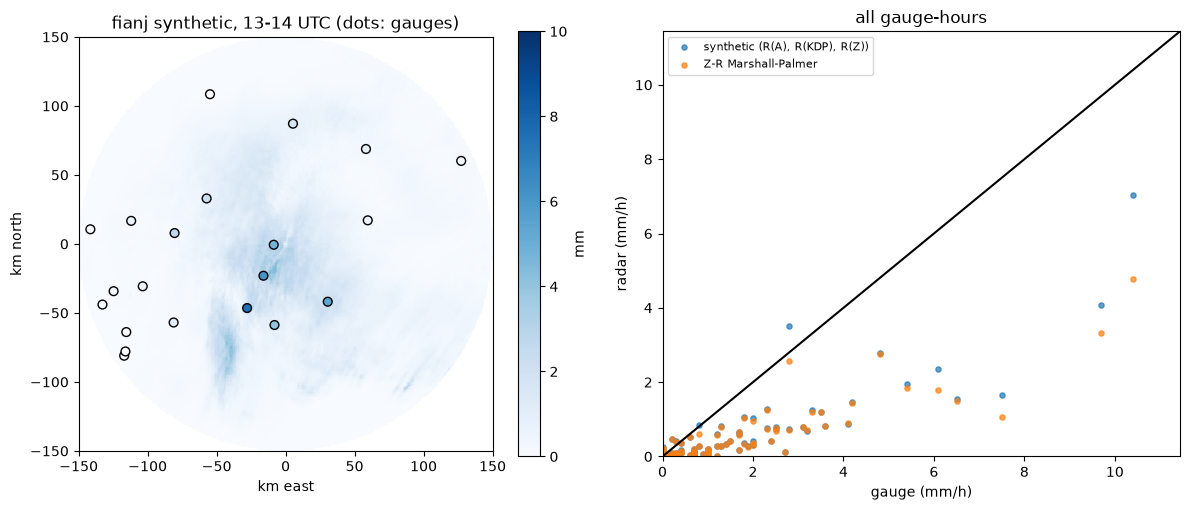

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
t = pd.Timestamp("2023-08-30 13:00")
f = rad["synthetic"]["RAIN"].sel(time=t).values
gt = ok[ok.time == t]
p = axes[0].pcolormesh(x, y, np.ma.masked_invalid(f), cmap="Blues", vmin=0, vmax=10, shading="auto")
axes[0].scatter(gt.gx, gt.gy, c=gt.gauge_mm, cmap="Blues", vmin=0, vmax=10, s=40, edgecolors="k")
axes[0].set(title=f"fianj synthetic, {t:%H}-{t.hour + 1:02d} UTC (dots: gauges)", aspect=1, xlabel="km east", ylabel="km north")
fig.colorbar(p, ax=axes[0], label="mm")
for k, c in [("synthetic", "C0"), ("marshall_palmer", "C1")]:
    axes[1].scatter(ok["gauge_mm"], ok[k], s=14, color=c, alpha=0.7, label=RATES[k])
lim = max(ok["gauge_mm"].max(), 1) * 1.1
axes[1].plot([0, lim], [0, lim], "k")
axes[1].set(xlim=(0, lim), ylim=(0, lim), xlabel="gauge (mm/h)", ylabel="radar (mm/h)", title="all gauge-hours")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG}/15_fianj_cband.png", dpi=100)
plt.show()

## 3. Merging with this few gauges (leave-one-out)

In [6]:
loo = []
for t, gt in ok.groupby("time"):
    field = rad["synthetic"]["RAIN"].sel(time=t).values
    for m in ["radar only", "MFB", "conditional merging", "KED"]:
        loo.append(pd.DataFrame(dict(method=m, gauge=gt["gauge_mm"].values,
                                     est=leave_one_out(m, field, x, y, gt["gx"].values, gt["gy"].values, gt["gauge_mm"].values))))
loo = pd.concat(loo)
s = pd.DataFrame([dict(method=m, **stats(d["est"].values, d["gauge"].values)) for m, d in loo.groupby("method", sort=False)])
display(Markdown("**Leave-one-out at the gauges**\n\n" + s.round(2).to_markdown(index=False)))

**Leave-one-out at the gauges**

| method              |   n |   bias |   MAE |   corr |
|:--------------------|----:|-------:|------:|-------:|
| radar only          |  84 |   0.36 |  1.08 |   0.86 |
| MFB                 |  84 |   1.03 |  0.76 |   0.87 |
| conditional merging |  84 |   1.02 |  0.62 |   0.88 |
| KED                 |  84 |   1.02 |  0.63 |   0.88 |

## Takeaways
- **The chain runs unchanged on a European C-band radar.** Same code from raw files to hourly totals: the ODIM
  reader, the health check (it found stored noise and a 66 deg system PHIDP offset, both handled), QVP melting
  layer (bottom 2.7 km, consistent with the 2.4 km 0 C prior), VPR, blockage, hybrid scan and motion-following totals.
- **The pattern is right, the amount is not.** Radar and gauges correlate at 0.86-0.88, but the radar sees only about
  a third of the gauge rain (bias 0.32-0.36), with plain Marshall-Palmer as with the synthetic estimate.
- **It is a site-wide factor, not a range effect.** The deficit is about the same at every gauge, from 9 km to 140 km
  from the radar (radar 0.3-0.45 of gauge), and does not go away with a one-hour time shift or a 10 km location
  tolerance. Corrections that depend on range (VPR, blockage, attenuation along the path) cannot cause it. Two
  candidates remain: a reflectivity calibration about 5-8 dB low, or a wet radome (water on the antenna cover
  attenuates C band in every direction; the gauge 9 km from the radar shows it was raining at the site). R(A)
  agrees with R(Z) where both exist (ratio 0.98), which does not settle it: with the band-default alpha it covers
  only 28 % of rain gates. A neighbouring radar seeing the same rain (the mosaic stage) can separate the two.
- **Gauges fix the amount.** Even with only 21 gauges, conditional merging and KED cut the error at left-out gauges
  by about 42 % (MAE 1.08 -> 0.62 mm) and bring the bias to 1.02; a single mean-field factor gets 30 %.
- **Not available here:** a gauge-corrected national reference like MRMS, and the drop-size-adaptive alpha (an
  S-band method).